## Создание окружения Python 3.11


In [1]:
import subprocess
import sys
from pathlib import Path

subprocess.run([sys.executable, "-m", "pip", "install", "uv"], check=True)
env_dir = Path("/kaggle/working/mm-env")
env_python = env_dir / "bin" / "python"
if not env_python.exists():
    subprocess.run([sys.executable, "-m", "uv", "venv",
                    "--python", "3.11", "--seed", str(env_dir)], check=True)

subprocess.run([str(env_python), "--version"], check=True)
subprocess.run([str(env_python), "-m", "pip", "install", "ipykernel"], check=True)
subprocess.run([str(env_python), "-m", "ipykernel", "install", "--user",
                "--name", "reproduction-py311",
                "--display-name", "Python 3.11 (reproduction)"], check=True)
print("Создано ядро Python 3.11 (reproduction) в VS Code.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 87.7 MB/s eta 0:00:00


Using CPython 3.11.17
Creating virtual environment with seed packages at: mm-env
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
 + packaging==26.3
 + pip==26.2.1
 + setuptools==84.0.0
 + wheel==0.48.0
Activate with: source mm-env/bin/activate


Python 3.11.17
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 46.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 639.0/639.0 kB 20.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 117.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 888.5/888.5 kB 28.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 769.8/769.8 kB 27.9 MB/s  0:00:00

Installed kernelspec reproduction-py311 in /root/.local/share/jupyter/kernels/reproduction-py311
Создано ядро Python 3.11 (reproduction) в VS Code.


## Установка кода и библиотек


In [ ]:
from pathlib import Path
import subprocess

REPO = Path("/kaggle/working/hw2")
LIBRARY = REPO / "sparse_kernel_regression" / "Library"
PYTHON = Path("/kaggle/working/mm-env/bin/python")
if not REPO.exists():
    subprocess.run(["git", "clone", "https://github.com/kostkornilov/hw2.git", str(REPO)], check=True)
assert (LIBRARY / "train_memory_mosaics.py").exists(), "Проверьте путь к Library."
subprocess.run([str(PYTHON), "-m", "pip", "install", "-r", "requirements.txt"], cwd=LIBRARY, check=True)
# ninja нужен для сборки авторского CUDA-оператора leaky average.
subprocess.run([str(PYTHON), "-m", "pip", "install", "ninja"], check=True)
subprocess.run([str(PYTHON), "-m", "pip", "install", "-e", ".", "--no-deps"], cwd=LIBRARY, check=True)


In [3]:
# Выполнить при обновлении кода, перед замером.
subprocess.run(["git", "pull", "--ff-only"], cwd=REPO, check=True)


Already up to date.


CompletedProcess(args=['git', 'pull', '--ff-only'], returncode=0)

## Language modeling


#### Скачивание и распаковка BabiStories


In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

data_dir = Path("/kaggle/working/babistories")
data_dir.mkdir(parents=True, exist_ok=True)
base_url = (
    "https://raw.githubusercontent.com/facebookresearch/"
    "MemoryMosaics/main/BabiStories/data"
)

for i in range(1, 6):
    name = f"babistories-dataset.7z.{i:03d}"
    if (data_dir / name).exists():
        continue
    print("Downloading", name, flush=True)
    # Сначала скачиваем во временный файл, чтобы не принять неполную загрузку за архив.
    temporary = data_dir / (name + ".part")
    urlretrieve(f"{base_url}/{name}", temporary)
    temporary.replace(data_dir / name)


In [ ]:
import shutil
import subprocess

# Устанавливаем архиватор только если он отсутствует в сессии.
if shutil.which("7z") is None:
    subprocess.run(["sudo", "apt-get", "update"], check=True)
    subprocess.run(["sudo", "apt-get", "install", "-y", "p7zip-full"], check=True)

# 7z сам прочитает остальные части архива из той же папки.
subprocess.run([
    "7z", "x", str(data_dir / "babistories-dataset.7z.001"),
    f"-o{data_dir}", "-aos",
], check=True)


In [24]:
for path in sorted(data_dir.rglob("*.txt")):
    print(path.relative_to(data_dir), f"{path.stat().st_size / 1024**2:.1f} MiB")


traindataset.txt 1880.0 MiB
valdataset.txt 18.8 MiB


#### Токенизация готовых train/val


In [ ]:
import json
import shutil

TOKEN_DIR = LIBRARY / "memory_mosaics" / "data" / "BabiStories"
STATS_PATH = TOKEN_DIR / "dataset_stats.json"
if not (STATS_PATH.exists() and (TOKEN_DIR / "train.bin").exists() and (TOKEN_DIR / "val.bin").exists()):
    subprocess.run([
        str(PYTHON), str(TOKEN_DIR / "prepare.py"),
        "--train-file", str(data_dir / "traindataset.txt"),
        "--val-file", str(data_dir / "valdataset.txt"),
        "--output-dir", str(TOKEN_DIR),
    ], check=True)
stats = json.loads(STATS_PATH.read_text())
print(json.dumps(stats, indent=2))
for split, expected in {"train": 474704907, "val": 4749107}.items():
    actual = stats[split]["tokens"]
    assert actual == expected, f"{split}: {actual} токенов вместо {expected}; проверьте данные."


### Полная конфигурация и длина замера


In [33]:
from datetime import datetime

METHODS = ["softmax", "epanechnikov", "relumax"]
LABELS = {"softmax": "Gaussian / softmax", "epanechnikov": "Epanechnikov / sparsemax",
          "relumax": "1-ReLUmax"}
GPU_IDS = [0, 1]
MICRO_BATCH = 8
GLOBAL_BATCH = 512
MEASURE_STEPS = 24
WARMUP_STEPS = 8  # Прогрев для замера, не LR warmup модели.
FULL_STEPS = 80000
FULL_EVAL_INTERVAL = 1000

assert GLOBAL_BATCH % (MICRO_BATCH * len(GPU_IDS)) == 0
assert MEASURE_STEPS % 2 == 0 and 0 < WARMUP_STEPS < MEASURE_STEPS // 2
ACCUMULATION = GLOBAL_BATCH // (MICRO_BATCH * len(GPU_IDS))
RESULTS = Path("/kaggle/working/results/timing/language_modeling") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RESULTS.mkdir(parents=True, exist_ok=True)

# Параметры полного обучения. В коротком запуске ниже меняются только
# число шагов, частота evaluation и частота печати лога.
FULL_CONFIG = {
    "seed": 1337, "attention_backend": "adasplash", "dtype": "float16", "compile": True,
    "n_layer": 1, "n_embd": 768, "n_head": 12, "pmem_size": 2688, "block_size": 512,
    "batch_size": MICRO_BATCH, "gradient_accumulation_steps": ACCUMULATION,
    "max_iters": FULL_STEPS, "learning_rate": 5e-3, "min_lr": 1e-4,
    "weight_decay": 0.1, "beta1": 0.9, "beta2": 0.95, "grad_clip": 1.0,
    "warmup_iters": 2000, "lr_decay_iters": 80000, "decay_type": "cosine",
    "eval_interval": FULL_EVAL_INTERVAL, "eval_iters": 10, "log_interval": 100,
    "save_checkpoint_interval": FULL_STEPS,
}
print(f"1 слой; global batch: {MICRO_BATCH} × {len(GPU_IDS)} × {ACCUMULATION} = {GLOBAL_BATCH}")
print(f"Замер: {MEASURE_STEPS} шагов на метод; прогноз: {FULL_STEPS:,} шагов на метод.")
print("Новый каталог замеров:", RESULTS)

1 слой; global batch: 8 × 2 × 32 = 512
Замер: 24 шагов на метод; прогноз: 80,000 шагов на метод.
Новый каталог замеров: /kaggle/working/results/timing/language_modeling/20261010_063135_385657


### Проверка окружения


In [39]:
import json
import shutil

subprocess.run([str(PYTHON), "-c", f"""
import torch
from importlib.metadata import version
from adasplash import adasplash_no_block_mask
assert torch.cuda.is_available()
assert version("torch").split("+")[0] == "2.4.1"
assert version("adasplash") == "0.1.1b0"
assert version("triton") == "3.0.0"
for i in {GPU_IDS!r}:
    assert 0 <= i < torch.cuda.device_count()
    print(i, torch.cuda.get_device_name(i), torch.cuda.get_device_capability(i))
print("torch:", torch.__version__, "AdaSplash:", version("adasplash"), "Triton:", version("triton"))
"""], check=True)
(RESULTS / "environment.txt").write_text(
    subprocess.check_output([str(PYTHON), "-m", "pip", "freeze"], text=True))
shutil.copy2(STATS_PATH, RESULTS / "dataset_stats.json")

0 Tesla T4 (7, 5)
1 Tesla T4 (7, 5)
torch: 2.4.1+cu121 AdaSplash: 0.1.1b0 Triton: 3.0.0


PosixPath('/kaggle/working/results/timing/language_modeling/20261010_063135_385657/dataset_stats.json')

### Короткие запуски и сбор замеров


In [ ]:
import math
import os
import re
import statistics
import time


def benchmark(method):
    out_dir = RESULTS / "runs"
    run_dir = out_dir / method
    assert not run_dir.exists(), "Для повторного замера выполните ячейку конфигурации заново."
    run_dir.mkdir(parents=True)
    parameters = {**FULL_CONFIG, "method": method, "out_dir": str(out_dir),
                  "max_iters": MEASURE_STEPS, "eval_interval": MEASURE_STEPS // 2,
                  "log_interval": 1}
    command = [str(PYTHON), "-m", "torch.distributed.run", "--standalone",
               f"--nproc_per_node={len(GPU_IDS)}", "train_memory_mosaics.py"]
    for key, value in parameters.items():
        command += [f"--{key}", str(value)]
    (run_dir / "run_config.json").write_text(json.dumps({
        "full_config": FULL_CONFIG, "benchmark_parameters": parameters,
        "command": command, "gpu_ids": GPU_IDS,
        "repository_commit": subprocess.check_output(
            ["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip(),
    }, indent=2))
    environment = os.environ.copy()
    environment.update(CUDA_VISIBLE_DEVICES=",".join(map(str, GPU_IDS)),
                       PYTHONUNBUFFERED="1", OMP_NUM_THREADS="1")
    environment.setdefault("MAX_JOBS", "2")
    print(f"\n{LABELS[method]}: {MEASURE_STEPS} шагов на {len(GPU_IDS)} GPU", flush=True)
    started = time.monotonic()
    with subprocess.Popen(command, cwd=LIBRARY, env=environment,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
        return_code = process.wait()
    if return_code:
        raise subprocess.CalledProcessError(return_code, command)
    elapsed = time.monotonic() - started

    log = (run_dir / "train.log").read_text()
    samples = [(int(step), float(ms) / 1000) for step, ms in re.findall(
        r"iter (\d+): loss .*?time ([\d.]+)ms / step", log)]
    assert [step for step, _ in samples] == list(range(MEASURE_STEPS))
    stable = [seconds for step, seconds in samples if step >= WARMUP_STEPS]
    evaluation = [float(value) for value in re.findall(
        r"\[timing\] evaluation \+ checkpoint: ([\d.]+)s", log)]
    assert len(evaluation) == 2, "Нужен обновлённый train_memory_mosaics.py с замерами evaluation."
    history = json.loads((run_dir / "loss_history.json").read_text())
    assert history["iter"][-1] == MEASURE_STEPS and (run_dir / "ckpt.pt").exists()
    assert all(math.isfinite(value) for field in ("train", "val") for value in history[field])
    step_seconds = statistics.median(stable)
    eval_seconds = statistics.mean(evaluation)
    # Остаток wall time учитывает запуск процессов, компиляцию и прогрев.
    startup_seconds = max(0, elapsed - MEASURE_STEPS * step_seconds - sum(evaluation))
    training_seconds = FULL_STEPS * step_seconds
    evaluation_count = (FULL_STEPS - 1) // FULL_EVAL_INTERVAL + 1
    result = {
        "method": method, "step_seconds": step_seconds,
        "step_min_seconds": min(stable), "step_max_seconds": max(stable),
        "evaluation_checkpoint_seconds": eval_seconds,
        "startup_warmup_seconds": startup_seconds, "benchmark_wall_seconds": elapsed,
        "full_steps": FULL_STEPS, "evaluation_count": evaluation_count,
        "training_hours": training_seconds / 3600,
        "full_hours": (training_seconds + evaluation_count * eval_seconds + startup_seconds) / 3600,
    }
    (run_dir / "timing.json").write_text(json.dumps(result, indent=2))
    return result


timings = []
for method in METHODS:
    timings.append(benchmark(method))


Gaussian / softmax: 24 шагов на 2 GPU


### Сколько длилось бы полное обучение


In [40]:
import csv
from IPython.display import Markdown, display

# Читаем сохранённые замеры: ячейка работает и после перезапуска ядра,
# если RESULTS указывает на каталог завершённого замера.
timings = [json.loads((RESULTS / "runs" / method / "timing.json").read_text())
           for method in METHODS]
with (RESULTS / "timing_summary.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(timings[0]))
    writer.writeheader()
    writer.writerows(timings)

rows = ["| Метод | Секунд/шаг | Диапазон после прогрева, с | Только обучение, ч | С evaluation и сохранением, ч |",
        "|---|---:|---:|---:|---:|"]
for result in timings:
    rows.append(f"| {LABELS[result['method']]} | {result['step_seconds']:.3f} | "
                f"{result['step_min_seconds']:.3f}–{result['step_max_seconds']:.3f} | "
                f"{result['training_hours']:.1f} | {result['full_hours']:.1f} |")
rows.append(f"| **Все три последовательно** | — | — | "
            f"**{sum(r['training_hours'] for r in timings):.1f}** | "
            f"**{sum(r['full_hours'] for r in timings):.1f}** |")
display(Markdown("\n".join(rows)))
print("Таблица и исходные замеры:", RESULTS)

| Метод | Секунд/шаг | Диапазон после прогрева, с | Только обучение, ч | С evaluation и сохранением, ч |
|---|---:|---:|---:|---:|
| Gaussian / softmax | 3.361 | 3.286–3.468 | 74.7 | 74.8 |
| Epanechnikov / sparsemax | 4.591 | 4.571–4.682 | 102.0 | 102.1 |
| 1-ReLUmax | 3.720 | 3.679–3.853 | 82.7 | 82.8 |
| **Все три последовательно** | — | — | **259.4** | **259.7** |

Таблица и исходные замеры: /kaggle/working/results/timing/language_modeling/20261010_063135_385657


### Проверка артефактов на коротких запусках


In [53]:
from pathlib import Path
import subprocess

REPO = Path("/kaggle/working/hw2")
PYTHON = Path("/kaggle/working/mm-env/bin/python")
METHODS = ["softmax", "epanechnikov", "relumax"]
# При необходимости замените None на Path("/kaggle/working/results/timing/language_modeling/...").
ARTIFACT_ROOT = None
if ARTIFACT_ROOT is None:
    if "RESULTS" in globals():
        ARTIFACT_ROOT = Path(RESULTS)
    else:
        candidates = sorted(Path("/kaggle/working/results/timing/language_modeling").glob("*/runs"))
        assert candidates, "Не найден каталог замеров; задайте ARTIFACT_ROOT явно."
        ARTIFACT_ROOT = candidates[-1].parent
print("Проверяем:", ARTIFACT_ROOT)
EXPORT_SCRIPT = REPO / "scripts" / "export_lm_artifacts.py"
assert EXPORT_SCRIPT.exists(), "Обновите репозиторий в Kaggle через git pull --ff-only."
subprocess.run([str(PYTHON), str(EXPORT_SCRIPT), str(ARTIFACT_ROOT),
                "--kind", "timing-smoke", "--methods", *METHODS], check=True)


Проверяем: /kaggle/working/results/timing/language_modeling/20261010_063135_385657
Validated 3 runs. Tables and curves: /kaggle/working/results/timing/language_modeling/20261010_063135_385657


CompletedProcess(args=['/kaggle/working/mm-env/bin/python', '/kaggle/working/hw2/scripts/export_lm_artifacts.py', '/kaggle/working/results/timing/language_modeling/20261010_063135_385657', '--kind', 'timing-smoke', '--methods', 'softmax', 'epanechnikov', 'relumax'], returncode=0)

Run kind: timing-smoke

| Method | Steps | Final train loss | Final val loss | Best observed val loss | Step |
|---|---:|---:|---:|---:|---:|
| Gaussian / softmax | 24 | 10.789020 | 10.788420 | 10.788420 | 24 |
| Epanechnikov / sparsemax | 24 | 10.797332 | 10.796805 | 10.796805 | 24 |
| 1-ReLUmax | 24 | 10.794430 | 10.793846 | 10.793846 | 24 |

ckpt.pt contains the final model. Best observed loss refers to recorded evaluations;
a separate checkpoint for the best step is not retained.


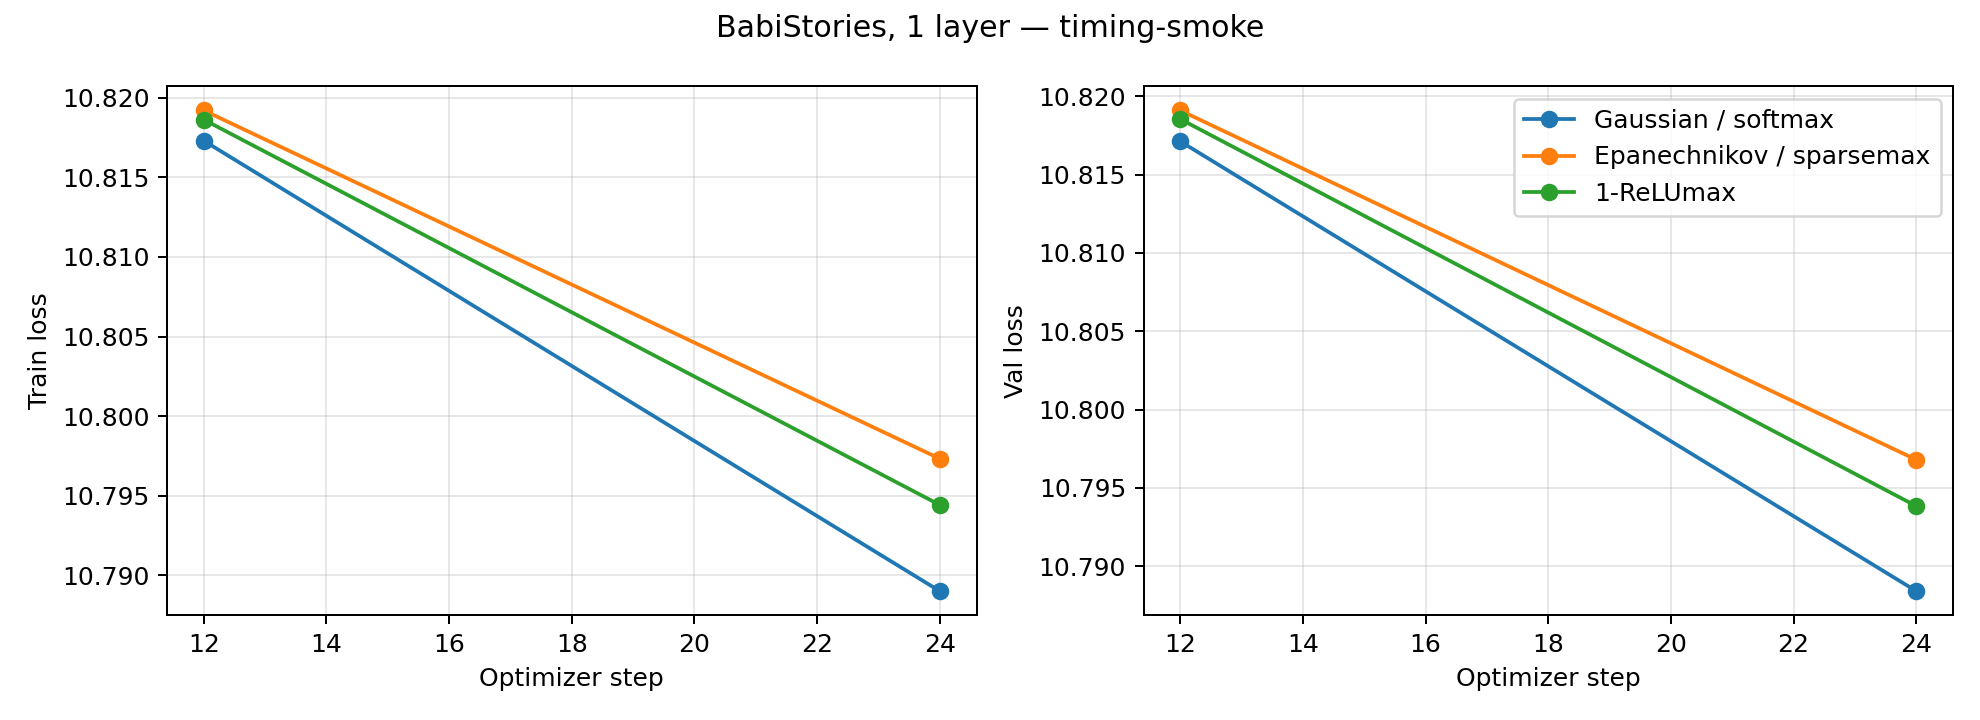

Проверка пройдена. Исходные артефакты:
runs/softmax/ckpt.pt: 523.17 MiB
runs/softmax/loss_history.json: 0.00 MiB
runs/softmax/metrics.csv: 0.00 MiB
runs/softmax/train.log: 0.00 MiB
runs/softmax/run_config.json: 0.00 MiB
runs/epanechnikov/ckpt.pt: 523.17 MiB
runs/epanechnikov/loss_history.json: 0.00 MiB
runs/epanechnikov/metrics.csv: 0.00 MiB
runs/epanechnikov/train.log: 0.00 MiB
runs/epanechnikov/run_config.json: 0.00 MiB
runs/relumax/ckpt.pt: 523.17 MiB
runs/relumax/loss_history.json: 0.00 MiB
runs/relumax/metrics.csv: 0.00 MiB
runs/relumax/train.log: 0.00 MiB
runs/relumax/run_config.json: 0.00 MiB
Все файлы для скачивания: /kaggle/working/results/timing/language_modeling/20261010_063135_385657


In [54]:
import json
from IPython.display import Image, Markdown, display

display(Markdown((ARTIFACT_ROOT / "results_summary.md").read_text()))
display(Image(filename=str(ARTIFACT_ROOT / "loss_curves.png")))
validation = json.loads((ARTIFACT_ROOT / "artifact_validation.json").read_text())
assert validation["status"] == "passed"
print("Проверка пройдена. Исходные артефакты:")
for name, item in validation["artifacts"].items():
    print(f"{name}: {item['bytes'] / 1024**2:.2f} MiB")
print("Все файлы для скачивания:", ARTIFACT_ROOT)


### Скачивание артефактов


In [46]:
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

assert (ARTIFACT_ROOT / "artifact_validation.json").exists(), "Сначала выполните проверку артефактов."
archive = Path("/kaggle/working") / f"lm_artifacts_{ARTIFACT_ROOT.name}.zip"
with ZipFile(archive, "w", compression=ZIP_DEFLATED) as bundle:
    for path in sorted(ARTIFACT_ROOT.rglob("*")):
        if path.is_file() and path.suffix != ".pt":
            bundle.write(path, arcname=str(Path(ARTIFACT_ROOT.name) / path.relative_to(ARTIFACT_ROOT)))
print(f"Архив для отчёта: {archive} ({archive.stat().st_size / 1024**2:.2f} MiB)")
display(FileLink(str(archive)))
print("Checkpoints отдельно:")
for method in METHODS:
    checkpoint = ARTIFACT_ROOT / "runs" / method / "ckpt.pt"
    print(f"{method}: {checkpoint.stat().st_size / 1024**2:.1f} MiB")
    display(FileLink(str(checkpoint)))


Архив для отчёта: /kaggle/working/lm_artifacts_20261010_063135_385657.zip (0.16 MiB)


/kaggle/working/lm_artifacts_20261010_063135_385657.zip

Checkpoints отдельно:
softmax: 523.2 MiB


/kaggle/working/results/timing/language_modeling/20261010_063135_385657/runs/softmax/ckpt.pt

epanechnikov: 523.2 MiB


/kaggle/working/results/timing/language_modeling/20261010_063135_385657/runs/epanechnikov/ckpt.pt

relumax: 523.2 MiB


/kaggle/working/results/timing/language_modeling/20261010_063135_385657/runs/relumax/ckpt.pt

## In-context learning: RegBench 1k, три механизма attention


In [13]:
from pathlib import Path
from datetime import datetime
import subprocess
import json
import os
import shutil

REPO = Path("/kaggle/working/hw2")
PYTHON = Path("/kaggle/working/mm-env/bin/python")
ICL_SOURCE = Path("/kaggle/working/seq_icl")
ICL_COMMIT = "9b9223d15348b5a415fb453ed988ed5f7ab9fbdc"
ICL_PROBE = REPO / "scripts/run_icl_probe.py"
ICL_EXAMPLES = 1000
ICL_EPOCHS = 3
ICL_METHODS = ["softmax", "epanechnikov", "relumax"]
ICL_CACHE = Path(f"/kaggle/working/regbench/dfa_{ICL_EXAMPLES}_seed0.pt")
ICL_RESULTS = Path("/kaggle/working/results/timing/in_context_learning") / datetime.now().strftime("%Y%m%d_%H%M%S")
assert PYTHON.exists(), "Сначала создайте mm-env в начале ноутбука."
assert ICL_PROBE.exists(), "Сначала передайте новые scripts и правку ICLL на Kaggle через git push / git pull."
ICL_ENV = {**os.environ, "PYTHONHASHSEED": "0", "TOKENIZERS_PARALLELISM": "false"}
print("Артефакты:", ICL_RESULTS)


Артефакты: /kaggle/working/results/timing/in_context_learning/20261010_100940


### Подготовка кода и зависимостей


In [ ]:
subprocess.run([str(PYTHON), "-m", "pip", "install", "-r", str(REPO / "scripts/requirements-icl.txt")], check=True)
if not ICL_SOURCE.exists():
    subprocess.run(["git", "clone", "https://github.com/berlino/seq_icl.git", str(ICL_SOURCE)], check=True)
subprocess.run(["git", "checkout", ICL_COMMIT], cwd=ICL_SOURCE, check=True)
assert subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ICL_SOURCE, text=True).strip() == ICL_COMMIT
ICLL = REPO / "sparse_kernel_regression/ICLL"
for source, target in [
    (ICLL / "train.py", ICL_SOURCE / "train.py"),
    (ICLL / "src/models/sequence/mm.py", ICL_SOURCE / "src/models/sequence/mm.py"),
    (ICLL / "configs/experiment/dfa/mm.yaml", ICL_SOURCE / "configs/experiment/dfa/mm.yaml"),
]:
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, target)
registry = ICL_SOURCE / "src/utils/registry.py"
registration = '\nmodel["mm"] = "src.models.sequence.mm.StackAssoMem"\n'
if registration not in registry.read_text():
    registry.write_text(registry.read_text() + registration)
(ICL_SOURCE / "src/dataloaders/__init__.py").write_text("from . import dfa\nfrom .base import SequenceDataset\n")
subprocess.run([str(PYTHON), "-c", "import torch, pytorch_lightning, torchvision; print('torch', torch.__version__, 'Lightning', pytorch_lightning.__version__); assert torch.cuda.device_count() == 2; print([torch.cuda.get_device_name(i) for i in range(2)])"], env=ICL_ENV, check=True)
ICL_RESULTS.mkdir(parents=True, exist_ok=False)
(ICL_RESULTS / "environment.txt").write_text(subprocess.check_output([str(PYTHON), "-m", "pip", "freeze"], text=True))
(ICL_RESULTS / "repository_commit.txt").write_text(subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True))
(ICL_RESULTS / "regbench_commit.txt").write_text(ICL_COMMIT + "\n")


### Генерация и проверка данных


In [15]:
if not ICL_CACHE.exists():
    subprocess.run([str(PYTHON), str(ICL_PROBE), "prepare", "--source", str(ICL_SOURCE),
                    "--cache", str(ICL_CACHE), "--examples", str(ICL_EXAMPLES)], env=ICL_ENV, check=True)
ICL_DATA = json.loads(ICL_CACHE.with_suffix(".json").read_text())
assert ICL_DATA["examples"] == ICL_EXAMPLES
print(json.dumps(ICL_DATA, indent=2))


/kaggle/working/mm-env/lib/python3.11/site-packages/lightning_lite/__init__.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)
/kaggle/working/mm-env/lib/python3.11/site-packages/pydantic/_internal/_generate_schema.py:2309: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/kaggle/working/mm-env/lib/python3.11/site-packag

{
  "examples": 1000,
  "seed": 0,
  "pythonhashseed": "0",
  "dataset_config": {
    "_name_": "icl_dfa",
    "num_examples": 1000,
    "num_test_examples": 1000,
    "vocab_size": 20,
    "max_num_nodes": 12,
    "max_num_in_context_examples": 20,
    "min_num_in_context_examples": 10,
    "max_outgoing_edges": 4,
    "max_len_per_example": 50,
    "input_seq_len": 4096,
    "copy_method": "assoc_recall",
    "batch_size": 16
  },
  "generation_seconds": 14.027058453000336,
  "sha256": "30d1d35ee24c3746e9d42fd21b1650a01bb4c9d8d5aaff4d3f1cfb08bda7d9f1",
  "splits": {
    "train": {
      "examples": 1000,
      "padded_tokens": 657,
      "min_tokens": 156,
      "median_tokens": 372.0,
      "max_tokens": 657,
      "scored_tokens": 362186
    },
    "test": {
      "examples": 500,
      "padded_tokens": 670,
      "min_tokens": 171,
      "median_tokens": 371.0,
      "max_tokens": 670,
      "scored_tokens": 181089
    },
    "val": {
      "examples": 500,
      "padded_tokens": 

### Короткие запуски на двух T4 и финальная оценка


In [16]:
import time

for method in ICL_METHODS:
    run_dir = ICL_RESULTS / method
    assert not run_dir.exists(), "Для повторения задайте новый ICL_RESULTS."
    run_dir.mkdir()
    common = ["--source", str(ICL_SOURCE), "--cache", str(ICL_CACHE), "--output-dir", str(run_dir),
              "--examples", str(ICL_EXAMPLES), "--method", method]
    train_command = [str(PYTHON), "-m", "torch.distributed.run", "--standalone", "--nproc_per_node=2",
                     str(ICL_PROBE), "train", *common, "--epochs", str(ICL_EPOCHS)]
    eval_command = [str(PYTHON), str(ICL_PROBE), "evaluate", *common]
    (run_dir / "commands.json").write_text(json.dumps({"train": train_command, "evaluate": eval_command}, indent=2))
    print(f"{method}: {ICL_EPOCHS} эпох на двух T4", flush=True)
    start = time.perf_counter()
    with (run_dir / "train.log").open("w") as log:
        subprocess.run(train_command, env={**ICL_ENV, "CUDA_VISIBLE_DEVICES": "0,1"}, stdout=log, stderr=subprocess.STDOUT, check=True)
    print(f"Обучение и validation: {time.perf_counter() - start:.1f} с. Финальная оценка...", flush=True)
    with (run_dir / "evaluation.log").open("w") as log:
        subprocess.run(eval_command, env={**ICL_ENV, "CUDA_VISIBLE_DEVICES": "0"}, stdout=log, stderr=subprocess.STDOUT, check=True)
    print("Готово:", run_dir, flush=True)


softmax: 3 эпох на двух T4
Обучение и validation: 53.0 с. Финальная оценка...
Готово: /kaggle/working/results/timing/in_context_learning/20261010_100940/softmax
epanechnikov: 3 эпох на двух T4
Обучение и validation: 68.4 с. Финальная оценка...
Готово: /kaggle/working/results/timing/in_context_learning/20261010_100940/epanechnikov
relumax: 3 эпох на двух T4
Обучение и validation: 64.7 с. Финальная оценка...
Готово: /kaggle/working/results/timing/in_context_learning/20261010_100940/relumax


### Проверка артефактов и прогноз времени


Короткая проверка RegBench: это не результаты полного обучения.

| Method | Train s/epoch | Validation s/epoch | 200 epochs, h | Test accuracy | Test TVD | Last-token accuracy | Last-token TVD |
|---|---:|---:|---:|---:|---:|---:|---:|
| softmax | 8.31 | 3.68 | 0.85 | 21.46% | 89.12% | 22.60% | 88.91% |
| epanechnikov | 11.19 | 6.06 | 1.14 | 21.46% | 89.10% | 22.60% | 88.89% |
| relumax | 11.38 | 4.58 | 1.07 | 21.46% | 89.12% | 22.60% | 88.91% |

Прогноз включает validation на каждой эпохе, сохранение best/last и финальную оценку.
Первую эпоху исключаем из медианы; scheduler остаётся рассчитанным на 200 эпох.
Суммарный прогноз трёх методов: 3.06 ч вычислений.
Accuracy и TVD пересчитаны по всем позициям сохранённых тестовых предсказаний
по формулам авторского plot_ICL.py; это не отдельная last-token метрика.


Короткая проверка RegBench: это не результаты полного обучения.

| Method | Train s/epoch | Validation s/epoch | 200 epochs, h | Test accuracy | Test TVD | Last-token accuracy | Last-token TVD |
|---|---:|---:|---:|---:|---:|---:|---:|
| softmax | 8.31 | 3.68 | 0.85 | 21.46% | 89.12% | 22.60% | 88.91% |
| epanechnikov | 11.19 | 6.06 | 1.14 | 21.46% | 89.10% | 22.60% | 88.89% |
| relumax | 11.38 | 4.58 | 1.07 | 21.46% | 89.12% | 22.60% | 88.91% |

Прогноз включает validation на каждой эпохе, сохранение best/last и финальную оценку.
Первую эпоху исключаем из медианы; scheduler остаётся рассчитанным на 200 эпох.
Суммарный прогноз трёх методов: 3.06 ч вычислений.
Accuracy и TVD пересчитаны по всем позициям сохранённых тестовых предсказаний
по формулам авторского plot_ICL.py; это не отдельная last-token метрика.


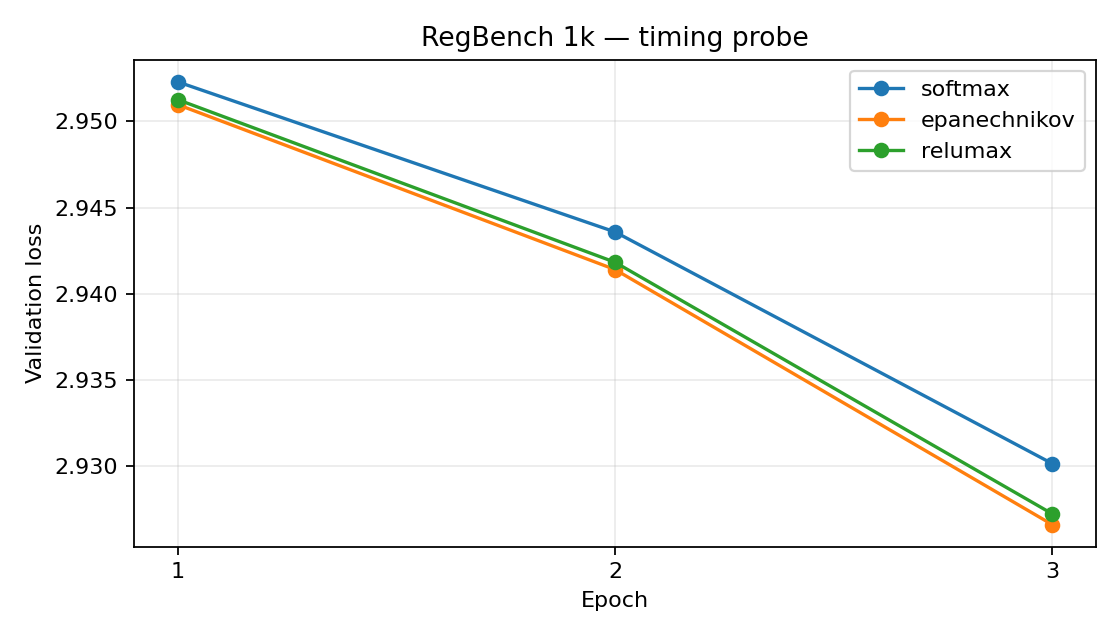

softmax passed файлов: 49
epanechnikov passed файлов: 49
relumax passed файлов: 49


In [20]:
from IPython.display import Markdown, Image, display

subprocess.run([str(PYTHON), str(ICL_PROBE), "summarize", "--source", str(ICL_SOURCE),
                "--output-dir", str(ICL_RESULTS)], env=ICL_ENV, check=True)
display(Markdown((ICL_RESULTS / "summary.md").read_text()))
display(Image(filename=str(ICL_RESULTS / "validation_loss.png")))
for method in ICL_METHODS:
    validation = json.loads((ICL_RESULTS / method / "artifact_validation.json").read_text())
    print(method, validation["status"], "файлов:", len(validation["files"]))


### Скачать результаты проверки


In [21]:
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink

assert all((ICL_RESULTS / method / "artifact_validation.json").exists() for method in ICL_METHODS)
ICL_ZIP = Path("/kaggle/working") / f"icl_probe_{ICL_RESULTS.name}.zip"
with ZipFile(ICL_ZIP, "w", ZIP_DEFLATED) as archive:
    for path in sorted(ICL_RESULTS.rglob("*")):
        if path.is_file():
            archive.write(path, path.relative_to(ICL_RESULTS))
display(FileLink(str(ICL_ZIP)))


/kaggle/working/icl_probe_20261010_100940.zip

## Length generalization: sort, 2 слоя, три механизма attention


In [4]:
from pathlib import Path
from datetime import datetime
import subprocess
import os
import json

REPO = Path('/kaggle/working/hw2')
PYTHON = Path('/kaggle/working/mm-env/bin/python')
LG_LIBRARY = REPO / 'sparse_kernel_regression/Library'
LG_PROBE = REPO / 'scripts/run_length_probe.py'
LG_METHODS = ['softmax', 'epanechnikov', 'relumax']
LG_STEPS, LG_WARMUP = 24, 8  # Для проверки запуска: 4, 1; для замера оставьте 24, 8.
LG_TEST_EXAMPLES = 128
LG_BUDGET_MINUTES = 150  # Общий бюджет всех трёх методов.
LG_FINAL_TEST_EXAMPLES = 1000  # Только для прогноза длительности финальной оценки.
LG_MICRO_BATCH, LG_EVAL_BATCH = 32, 8
LG_SEED = 1338
LG_DATA = Path('/kaggle/working/length_data') / f'sort_asentmax_be54bd3_{LG_STEPS * 256}_test{LG_TEST_EXAMPLES}_seed{LG_SEED}'
LG_RESULTS = Path('/kaggle/working/results/timing/length_generalization') / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
LG_ENV = {**os.environ, 'CUDA_VISIBLE_DEVICES': '0,1', 'PYTHONUNBUFFERED': '1',
          'OMP_NUM_THREADS': '1', 'MAX_JOBS': '2'}
assert PYTHON.exists() and LG_PROBE.exists(), 'Передайте scripts/run_length_probe.py в Kaggle; используем уже готовый mm-env.'
assert 256 % (2 * LG_MICRO_BATCH) == 0
assert 0 <= LG_WARMUP < LG_STEPS
LG_RESULTS.mkdir(parents=True, exist_ok=False)
print('Данные:', LG_DATA)
print('Артефакты:', LG_RESULTS)
print('Batch:', LG_MICRO_BATCH, '× 2 GPU ×', 256 // (2 * LG_MICRO_BATCH), 'накопления = 256')

Данные: /kaggle/working/length_data/sort_asentmax_be54bd3_6144_test128_seed1338
Артефакты: /kaggle/working/results/timing/length_generalization/20261010_120355_688155
Batch: 32 × 2 GPU × 4 накопления = 256


### Окружение и данные


In [5]:
subprocess.run([str(PYTHON), '-c', """
import torch
from adasplash import adasplash_no_block_mask
from importlib.metadata import version
assert torch.cuda.device_count() == 2
assert version('torch').split('+')[0] == '2.4.1'
assert version('adasplash') == '0.1.1b0'
assert version('triton') == '3.0.0'
for i in range(2):
    print(i, torch.cuda.get_device_name(i), flush=True)
"""], env=LG_ENV, check=True)
(LG_RESULTS / 'environment.txt').write_text(subprocess.check_output(
    [str(PYTHON), '-m', 'pip', 'freeze'], text=True))
(LG_RESULTS / 'repository_commit.txt').write_text(subprocess.check_output(
    ['git', 'rev-parse', 'HEAD'], cwd=REPO, text=True))
if not LG_DATA.exists():
    subprocess.run([str(PYTHON), str(LG_PROBE), 'prepare', '--library', str(LG_LIBRARY),
                    '--data', str(LG_DATA), '--examples', str(LG_STEPS * 256),
                    '--test-examples', str(LG_TEST_EXAMPLES), '--seed', str(LG_SEED)], check=True)
manifest = json.loads((LG_DATA / 'manifest.json').read_text())
assert manifest['generator']['commit'] == 'be54bd3f9cfb9f17c80a8d956ea827f5cf93d07d'
assert manifest['shards']['train']['examples'] == LG_STEPS * 256
assert manifest['generation']['seq_len'] == 64 and manifest['generation']['vary_len'] == 0
print('Источник данных:', manifest['generator']['url'])
print(manifest['shards'])

0 Tesla T4
1 Tesla T4


100%|██████████| 6144/6144 [00:00<00:00, 24616.71it/s]


Data validated: /kaggle/working/length_data/sort_asentmax_be54bd3_6144_test128_seed1338
Источник данных: https://raw.githubusercontent.com/deep-spin/asentmax/be54bd3f9cfb9f17c80a8d956ea827f5cf93d07d/scripts/generate_data.py
{'train': {'length': 64, 'examples': 6144, 'seed': 1338}, 'validation_64': {'length': 64, 'examples': 128, 'seed': 1338}, 'validation_128': {'length': 128, 'examples': 128, 'seed': 1338}, 'validation_256': {'length': 256, 'examples': 128, 'seed': 1338}, 'test_64': {'length': 64, 'examples': 128, 'seed': 1338}, 'test_128': {'length': 128, 'examples': 128, 'seed': 1338}, 'test_256': {'length': 256, 'examples': 128, 'seed': 1338}}


### Пробное обучение и оценка


In [6]:
import signal
import time


def lg_run(command, log_path, env):
    with log_path.open('w') as log:
        process = subprocess.Popen(command, cwd=LG_LIBRARY, env=env,
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, start_new_session=True)
        try:
            for line in process.stdout:
                log.write(line)
                log.flush()
                print(line, end='', flush=True)
            code = process.wait()
            if code:
                raise subprocess.CalledProcessError(code, command)
        except BaseException:
            if process.poll() is None:
                os.killpg(process.pid, signal.SIGTERM)
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    os.killpg(process.pid, signal.SIGKILL)
                    process.wait()
            raise


for method in LG_METHODS:
    run_dir = LG_RESULTS / method
    assert not run_dir.exists(), 'Для повторного запуска задайте новый LG_RESULTS.'
    common = ['--library', str(LG_LIBRARY), '--data', str(LG_DATA), '--output-dir', str(run_dir)]
    print(f'\n{method}: {LG_STEPS} шагов на двух T4', flush=True)
    train_command = [str(PYTHON), '-m', 'torch.distributed.run', '--standalone', '--nproc_per_node=2',
                     str(LG_PROBE), 'train', *common, '--method', method, '--steps', str(LG_STEPS),
                     '--warmup', str(LG_WARMUP), '--micro-batch', str(LG_MICRO_BATCH), '--seed', str(LG_SEED)]
    evaluation_command = [str(PYTHON), str(LG_PROBE), 'evaluate', *common, '--eval-batch', str(LG_EVAL_BATCH)]
    started = time.monotonic()
    lg_run(train_command, LG_RESULTS / f'{method}_train.log', LG_ENV)
    train_seconds = time.monotonic() - started
    print(f'Обучение закончено за {train_seconds:.1f} с. Оценка на 64/128/256...', flush=True)
    started = time.monotonic()
    lg_run(evaluation_command, LG_RESULTS / f'{method}_evaluation.log',
           {**LG_ENV, 'CUDA_VISIBLE_DEVICES': '0'})
    (run_dir / 'wall_timing.json').write_text(json.dumps({
        'train_seconds': train_seconds, 'evaluation_seconds': time.monotonic() - started,
    }, indent=2))
    (run_dir / 'commands.json').write_text(json.dumps({
        'train': train_command, 'evaluate': evaluation_command,
    }, indent=2))
    print('Готово:', run_dir, flush=True)


softmax: 24 шагов на двух T4
Using /root/.cache/torch_extensions/py311_cu121 as PyTorch extensions root...
Creating extension directory /root/.cache/torch_extensions/py311_cu121/wkv...
Using /root/.cache/torch_extensions/py311_cu121 as PyTorch extensions root...
Creating extension directory /root/.cache/torch_extensions/py311_cu121/wkv...
Detected CUDA files, patching ldflags
Emitting ninja build file /root/.cache/torch_extensions/py311_cu121/wkv/build.ninja...
/kaggle/working/mm-env/lib/python3.11/site-packages/torch/utils/cpp_extension.py:1965: UserWarning: TORCH_CUDA_ARCH_LIST is not set, all archs for visible cards are included for compilation. 
If this is not desired, please set os.environ['TORCH_CUDA_ARCH_LIST'].
  warnings.warn(
Building extension module wkv...
Using envvar MAX_JOBS (2) as the number of workers...
[1/3] /usr/local/cuda/bin/nvcc --generate-dependencies-with-compile --dependency-output wkv_cuda.cuda.o.d -DTORCH_EXTENSION_NAME=wkv -DTORCH_API_INCLUDE_EXTENSION_H -

### Проверка артефактов и времени


Проверка формата артефактов sort завершена. Короткий запуск не оценивает качество воспроизведения.

Общий бюджет: 150 мин; тест: 1000 примеров на длину.

| Метод | с/шаг после прогрева | 40M примеров, ч | шагов в бюджете метода |
|---|---:|---:|---:|
| softmax | 0.373 | 16.22 | 7921 |
| epanechnikov | 0.472 | 20.51 | 6157 |
| relumax | 0.412 | 17.91 | 7209 |

Общее число шагов по самому медленному методу: 6157; примеров на метод: 1576192.
Прогноз включает запуск, прогрев, сохранение и экстраполяцию финальной оценки,
но не дополнительные validation/checkpoints и не генерацию полного датасета.
Оценка по короткому замеру после прогрева приблизительная; оставьте запас времени.
Архитектура соответствует статье; авторский генератор asentmax, train length 64, один seed, FP16, compile=False.
LR schedule в пробе оставлен авторским. Изменение расписания длительного запуска пока не согласовано.


method,length,multiplier,examples,loss,exact_accuracy,token_accuracy,seconds
softmax,64,1,128,3.270934358239174,0.0,0.56591796875,0.6407693300000119
softmax,128,2,128,3.144159123301506,0.0,0.75445556640625,0.263620663000097
softmax,256,4,128,3.0637376755476,0.0,0.875,0.43868598200003817
epanechnikov,64,1,128,3.296260893344879,0.0,0.56591796875,6.271044299999971
epanechnikov,128,2,128,3.1838426291942596,0.0,0.75445556640625,0.4289948599999889
epanechnikov,256,4,128,3.1184194684028625,0.0,0.875,0.9411253380000062
relumax,64,1,128,3.288669779896736,0.0,0.56591796875,0.6645757430000003
relumax,128,2,128,3.1655794978141785,0.0,0.75445556640625,0.30674153400002524
relumax,256,4,128,3.0855173766613007,0.0,0.875,0.5999742120000064



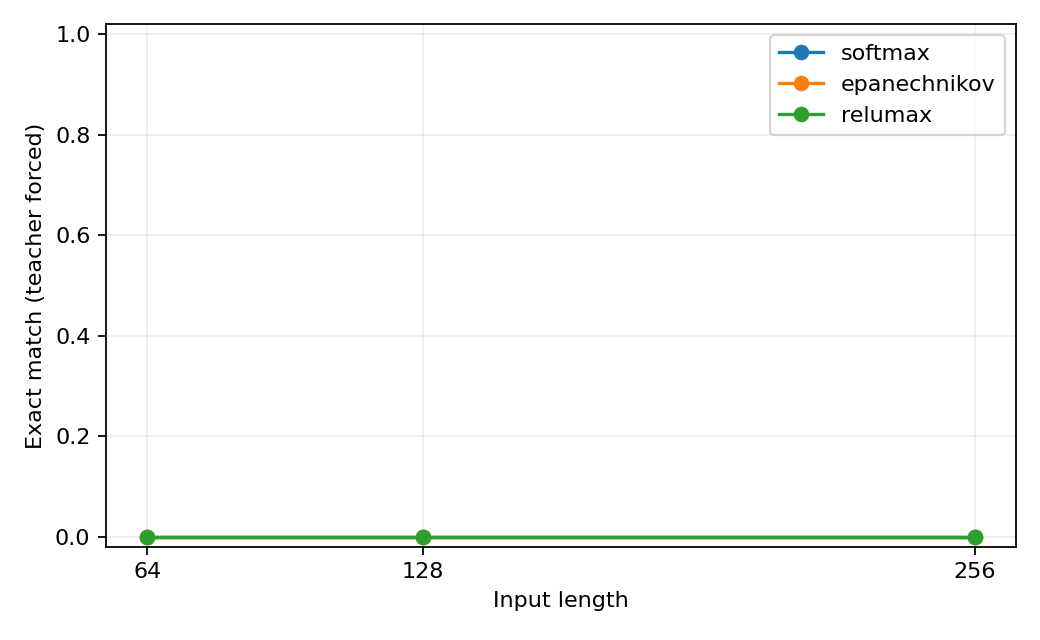

softmax True
epanechnikov True
relumax True


In [7]:
from IPython.display import Markdown, Image, display

subprocess.run([str(PYTHON), str(LG_PROBE), 'summarize', '--library', str(LG_LIBRARY),
                '--data', str(LG_DATA), '--output-dir', str(LG_RESULTS),
                '--budget-minutes', str(LG_BUDGET_MINUTES),
                '--evaluation-examples', str(LG_FINAL_TEST_EXAMPLES)], check=True)
display(Markdown((LG_RESULTS / 'results_summary.md').read_text()))
print((LG_RESULTS / 'results_summary.csv').read_text())
display(Image(filename=str(LG_RESULTS / 'length_accuracy.png')))
for method in LG_METHODS:
    print(method, json.loads((LG_RESULTS / method / 'artifact_validation.json').read_text())['valid'])

### Скачать артефакты


In [8]:
from zipfile import ZipFile, ZIP_DEFLATED

assert all((LG_RESULTS / m / 'artifact_validation.json').exists() for m in LG_METHODS)
LG_ZIP = Path('/kaggle/working') / f'length_probe_{LG_RESULTS.name}.zip'
with ZipFile(LG_ZIP, 'w', compression=ZIP_DEFLATED) as archive:
    for folder, prefix in [(LG_RESULTS, 'results'), (LG_DATA, 'data')]:
        for path in folder.rglob('*'):
            if path.is_file():
                archive.write(path, str(Path(prefix) / path.relative_to(folder)))
print('Архив для скачивания через панель Files Kaggle:', LG_ZIP)
print(f'Размер: {LG_ZIP.stat().st_size / 2**20:.1f} MiB')

Архив для скачивания через панель Files Kaggle: /kaggle/working/length_probe_20261010_120355_688155.zip
Размер: 260.1 MiB
